# Checkpoint 3: Core Model + Experimentation
## FinWise Lending - Credit Risk Project

**Deliverables in this notebook:**
1. Train the primary/champion model (XGBoost) with **3 hyperparameter
   configurations** (satisfies the "at least 2" requirement with margin).
2. Log every experiment (params, metrics, model, plots) to **MLflow**.
3. Compare all configs against each other AND against the Checkpoint 2
   baseline, on the exact same benchmark metrics (AUC, Gini, KS, Brier).
4. Select the best configuration with evidence and auto-write the report.

This notebook reuses `data_pipeline.py` and the **same fitted
preprocessor** saved in Checkpoint 2, so the baseline-vs-champion
comparison is apples-to-apples (no re-fit, no leakage, no drift).

## 1. Setup

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlflow
import mlflow.xgboost

from xgboost import XGBClassifier
from sklearn.metrics import (
    roc_auc_score, roc_curve, confusion_matrix, classification_report,
    brier_score_loss
)

from data_pipeline import run_pipeline, FinWisePreprocessor

warnings.filterwarnings("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("husl")

# Local MLflow tracking store, backed by SQLite - no external server needed.
# (Newer MLflow versions deprecated the plain './mlruns' file store, so we
# point at a local SQLite DB instead - still 100% local, single command to launch the UI.)
mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("finwise_champion_model")

print("Setup complete. MLflow tracking URI:", mlflow.get_tracking_uri())
print("Launch the UI later with:  mlflow ui --backend-store-uri sqlite:///mlflow.db")

2026/09/11 07:02:30 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/09/11 07:02:30 INFO mlflow.store.db.utils: Updating database tables


2026/09/11 07:02:30 INFO mlflow.tracking.fluent: Experiment with name 'finwise_champion_model' does not exist. Creating a new experiment.


Setup complete. MLflow tracking URI: sqlite:///mlflow.db
Launch the UI later with:  mlflow ui --backend-store-uri sqlite:///mlflow.db


## 2. Load Data via the Checkpoint 2 Pipeline

Reusing `run_pipeline` guarantees the exact same features, split, and
fitted preprocessor as the baseline model. We do NOT refit the
preprocessor here.

In [2]:
DATA_PATH = "finwise_loan_applications.csv"  # <-- point this at your real file

pipeline_output = run_pipeline(DATA_PATH, artifacts_dir="artifacts")

X_train, y_train = pipeline_output["X_train"], pipeline_output["y_train"]
X_val, y_val = pipeline_output["X_val"], pipeline_output["y_val"]
X_test, y_test = pipeline_output["X_test"], pipeline_output["y_test"]

print(f"Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

2026-09-11 07:02:30,827 | INFO | Loaded 5,000 rows and 13 columns from finwise_loan_applications.csv


2026-09-11 07:02:30,840 | INFO | Validation complete: 5,000 -> 5,000 rows (0 dropped, 0.0%)


2026-09-11 07:02:30,872 | INFO | Split: train=3,500 (70.0%)  val=500 (10.0%)  test=1,000 (20.0%)


2026-09-11 07:02:31,474 | INFO | Preprocessor fitted on 3,500 rows -> 23 features


2026-09-11 07:02:32,416 | INFO | Preprocessor saved to artifacts/preprocessor.pkl


Train: (3500, 23), Val: (500, 23), Test: (1000, 23)


In [3]:
# Load the Checkpoint 2 baseline benchmark for later comparison
with open("artifacts/evaluation_benchmark.json") as f:
    baseline_benchmark = json.load(f)

baseline_test_gini = baseline_benchmark["baseline_test"]["gini"]
baseline_test_auc = baseline_benchmark["baseline_test"]["auc"]
baseline_test_ks = baseline_benchmark["baseline_test"]["ks_statistic"]
print(f"Baseline (Logistic Regression) test Gini: {baseline_test_gini:.4f}")

Baseline (Logistic Regression) test Gini: 0.0956


## 3. Evaluation Helpers (same definitions as Checkpoint 2 - identical benchmark)

In [4]:
def gini_from_auc(auc):
    return 2 * auc - 1

def ks_statistic(y_true, y_pred_proba):
    df_ks = pd.DataFrame({"y": y_true, "p": y_pred_proba}).sort_values("p")
    df_ks["cum_good"] = (1 - df_ks["y"]).cumsum() / (1 - df_ks["y"]).sum()
    df_ks["cum_bad"] = df_ks["y"].cumsum() / df_ks["y"].sum()
    return (df_ks["cum_bad"] - df_ks["cum_good"]).abs().max()

def evaluate(y_true, y_pred_proba, threshold=0.5):
    auc = roc_auc_score(y_true, y_pred_proba)
    return {
        "auc": auc,
        "gini": gini_from_auc(auc),
        "ks_statistic": ks_statistic(y_true, y_pred_proba),
        "brier_score": brier_score_loss(y_true, y_pred_proba),
        "n": len(y_true),
    }

## 4. Hyperparameter Configurations

Three configurations spanning the usual trade-off space: a fast/shallow
model, a balanced default, and a deep/heavily-regularized model. Each is
trained with early stopping on the validation set so `n_estimators` is a
ceiling, not a fixed target.

In [5]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

configs = {
    "config_A_shallow_fast": {
        "n_estimators": 300,
        "max_depth": 3,
        "learning_rate": 0.1,
        "subsample": 0.9,
        "colsample_bytree": 0.9,
        "min_child_weight": 3,
        "reg_alpha": 0.0,
        "reg_lambda": 1.0,
        "scale_pos_weight": scale_pos_weight,
        "random_state": 42,
        "eval_metric": "auc",
    },
    "config_B_balanced_default": {
        "n_estimators": 500,
        "max_depth": 6,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "min_child_weight": 5,
        "gamma": 0.1,
        "reg_alpha": 0.1,
        "reg_lambda": 1.0,
        "scale_pos_weight": scale_pos_weight,
        "random_state": 42,
        "eval_metric": "auc",
    },
    "config_C_deep_regularized": {
        "n_estimators": 800,
        "max_depth": 8,
        "learning_rate": 0.03,
        "subsample": 0.7,
        "colsample_bytree": 0.7,
        "min_child_weight": 8,
        "gamma": 0.2,
        "reg_alpha": 0.3,
        "reg_lambda": 2.0,
        "scale_pos_weight": scale_pos_weight,
        "random_state": 42,
        "eval_metric": "auc",
    },
}

print(f"Configurations to run: {list(configs.keys())}")

Configurations to run: ['config_A_shallow_fast', 'config_B_balanced_default', 'config_C_deep_regularized']


## 5. Train + Log Each Configuration to MLflow

In [6]:
EARLY_STOPPING_ROUNDS = 30
run_results = {}

for run_name, params in configs.items():
    print(f"\n{'='*60}\nTraining {run_name}\n{'='*60}")

    with mlflow.start_run(run_name=run_name) as run:
        # Log hyperparameters
        mlflow.log_params(params)
        mlflow.log_param("early_stopping_rounds", EARLY_STOPPING_ROUNDS)
        mlflow.log_param("n_features", X_train.shape[1])

        model = XGBClassifier(**params, early_stopping_rounds=EARLY_STOPPING_ROUNDS)
        model.fit(
            X_train, y_train,
            eval_set=[(X_train, y_train), (X_val, y_val)],
            verbose=False,
        )

        best_iteration = getattr(model, "best_iteration", params["n_estimators"])
        mlflow.log_metric("best_iteration", best_iteration)

        # Evaluate on train / val / test - identical metric definitions as baseline
        train_metrics = evaluate(y_train, model.predict_proba(X_train)[:, 1])
        val_metrics = evaluate(y_val, model.predict_proba(X_val)[:, 1])
        test_metrics = evaluate(y_test, model.predict_proba(X_test)[:, 1])

        for split_name, m in [("train", train_metrics), ("val", val_metrics), ("test", test_metrics)]:
            for metric_name, value in m.items():
                if metric_name != "n":
                    mlflow.log_metric(f"{split_name}_{metric_name}", value)

        # Log the model itself (XGBoost-native flavor - avoids the sklearn
        # flavor's skops serializer, which blocks XGBoost's own object types)
        mlflow.xgboost.log_model(model, name="model")

        run_results[run_name] = {
            "run_id": run.info.run_id,
            "params": params,
            "best_iteration": best_iteration,
            "train": train_metrics,
            "val": val_metrics,
            "test": test_metrics,
            "model": model,
        }

        print(f"  Best iteration: {best_iteration}")
        print(f"  Val  Gini: {val_metrics['gini']:.4f} | AUC: {val_metrics['auc']:.4f} | KS: {val_metrics['ks_statistic']:.4f}")
        print(f"  Test Gini: {test_metrics['gini']:.4f} | AUC: {test_metrics['auc']:.4f} | KS: {test_metrics['ks_statistic']:.4f}")
        print(f"  MLflow run_id: {run.info.run_id}")

print("\nAll configurations trained and logged to MLflow.")
print("Launch the MLflow UI with:  mlflow ui --backend-store-uri sqlite:///mlflow.db")


Training config_A_shallow_fast


  Best iteration: 22
  Val  Gini: 0.2179 | AUC: 0.6090 | KS: 0.2085
  Test Gini: 0.0768 | AUC: 0.5384 | KS: 0.0839
  MLflow run_id: 16d4929e09be43d5992087ce5370672d

Training config_B_balanced_default


  Best iteration: 11
  Val  Gini: 0.2466 | AUC: 0.6233 | KS: 0.2688
  Test Gini: 0.0462 | AUC: 0.5231 | KS: 0.0890
  MLflow run_id: 0ee79809c3914203b369e329d599e995

Training config_C_deep_regularized


  Best iteration: 22
  Val  Gini: 0.2149 | AUC: 0.6075 | KS: 0.2134
  Test Gini: 0.0106 | AUC: 0.5053 | KS: 0.0423
  MLflow run_id: 967c710a60044377942b464b0dc85b7e

All configurations trained and logged to MLflow.
Launch the MLflow UI with:  mlflow ui --backend-store-uri sqlite:///mlflow.db


## 6. Compare All Configurations (Evidence Table)

In [7]:
comparison_rows = []
for run_name, res in run_results.items():
    comparison_rows.append({
        "Config": run_name,
        "Best Iteration": res["best_iteration"],
        "Val AUC": res["val"]["auc"],
        "Val Gini": res["val"]["gini"],
        "Val KS": res["val"]["ks_statistic"],
        "Test AUC": res["test"]["auc"],
        "Test Gini": res["test"]["gini"],
        "Test KS": res["test"]["ks_statistic"],
        "Test Brier": res["test"]["brier_score"],
        "Train-Val Gini Gap": res["train"]["gini"] - res["val"]["gini"],  # overfit signal
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values("Val Gini", ascending=False).reset_index(drop=True)
print("=" * 100)
print("HYPERPARAMETER CONFIGURATION COMPARISON")
print("=" * 100)
print(comparison_df.round(4).to_string(index=False))

comparison_df.to_csv("artifacts/experiment_comparison.csv", index=False)

HYPERPARAMETER CONFIGURATION COMPARISON
                   Config  Best Iteration  Val AUC  Val Gini  Val KS  Test AUC  Test Gini  Test KS  Test Brier  Train-Val Gini Gap
config_B_balanced_default              11   0.6233    0.2466  0.2688    0.5231     0.0462   0.0890      0.2356              0.4672
    config_A_shallow_fast              22   0.6090    0.2179  0.2085    0.5384     0.0768   0.0839      0.2421              0.2448
config_C_deep_regularized              22   0.6075    0.2149  0.2134    0.5053     0.0106   0.0423      0.2301              0.6522


In [8]:
# Select best config by validation Gini (never pick on test - that would leak
# the "held-out" test set into model selection)
best_config_name = comparison_df.iloc[0]["Config"]
best_result = run_results[best_config_name]
best_model = best_result["model"]

print(f"\nBEST CONFIGURATION (by validation Gini): {best_config_name}")
print(f"  MLflow run_id: {best_result['run_id']}")
print(f"  Validation Gini: {best_result['val']['gini']:.4f}")
print(f"  Test Gini (final, unbiased estimate): {best_result['test']['gini']:.4f}")


BEST CONFIGURATION (by validation Gini): config_B_balanced_default
  MLflow run_id: 0ee79809c3914203b369e329d599e995
  Validation Gini: 0.2466
  Test Gini (final, unbiased estimate): 0.0462


## 7. Visual Evidence

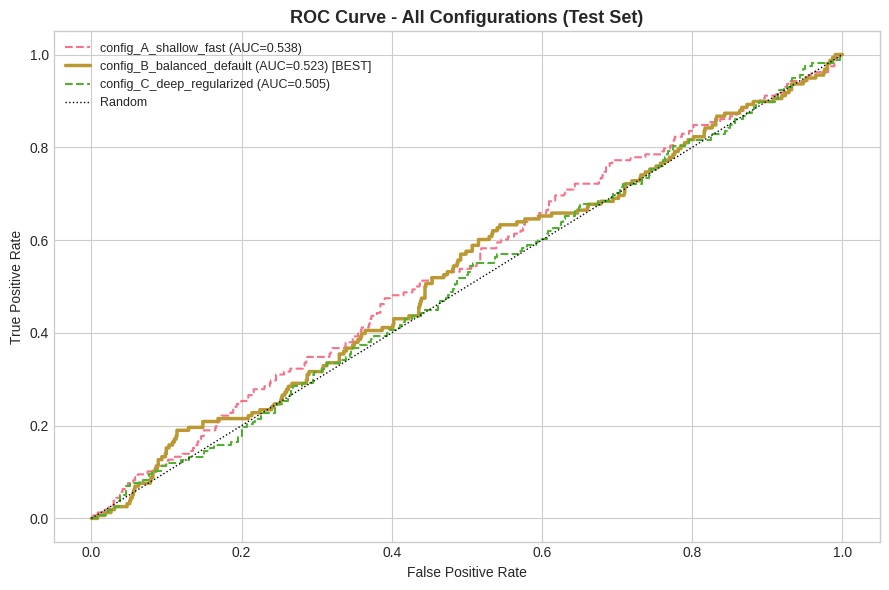

In [9]:
fig, ax = plt.subplots(figsize=(9, 6))
for run_name, res in run_results.items():
    fpr, tpr, _ = roc_curve(y_test, res["model"].predict_proba(X_test)[:, 1])
    style = "-" if run_name == best_config_name else "--"
    lw = 2.5 if run_name == best_config_name else 1.5
    ax.plot(fpr, tpr, style, linewidth=lw,
            label=f"{run_name} (AUC={res['test']['auc']:.3f})" + (" [BEST]" if run_name == best_config_name else ""))
ax.plot([0, 1], [0, 1], "k:", linewidth=1, label="Random")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curve - All Configurations (Test Set)", fontsize=13, fontweight="bold")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig("experiment_roc_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

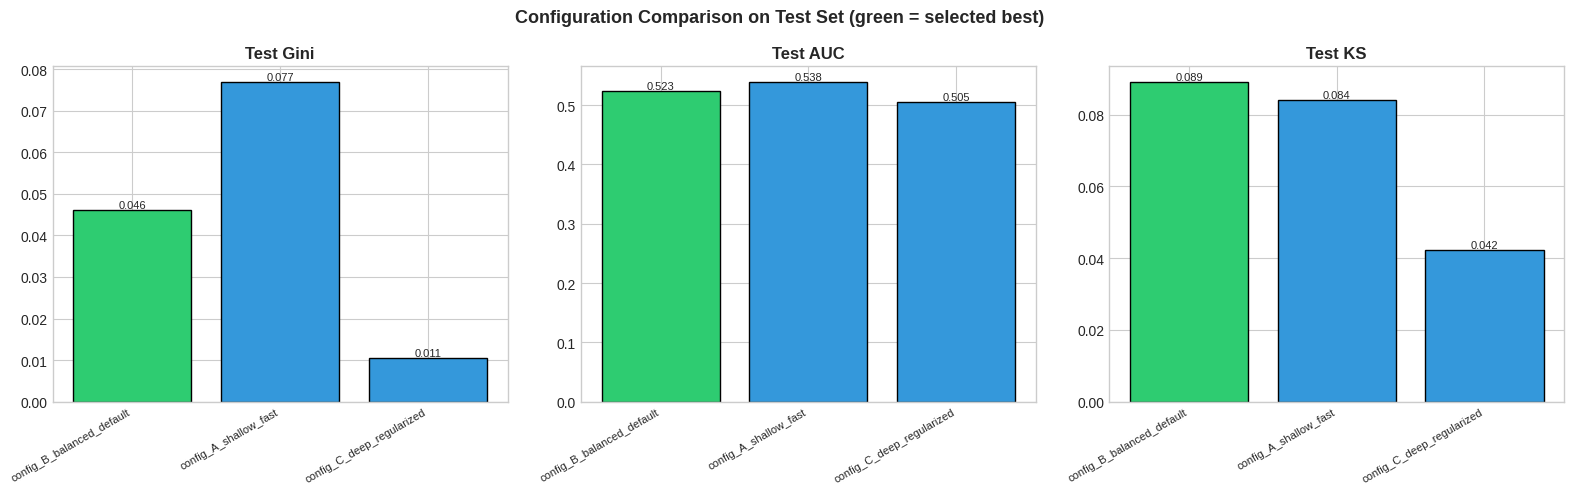

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics_to_plot = ["Test Gini", "Test AUC", "Test KS"]
colors_bar = ["#3498db" if c != best_config_name else "#2ecc71" for c in comparison_df["Config"]]

for ax, metric in zip(axes, metrics_to_plot):
    bars = ax.bar(comparison_df["Config"], comparison_df[metric], color=colors_bar, edgecolor="black")
    ax.set_title(metric, fontsize=12, fontweight="bold")
    ax.set_xticklabels(comparison_df["Config"], rotation=30, ha="right", fontsize=8)
    for bar, v in zip(bars, comparison_df[metric]):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f"{v:.3f}", ha="center", va="bottom", fontsize=8)

plt.suptitle("Configuration Comparison on Test Set (green = selected best)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("experiment_metric_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

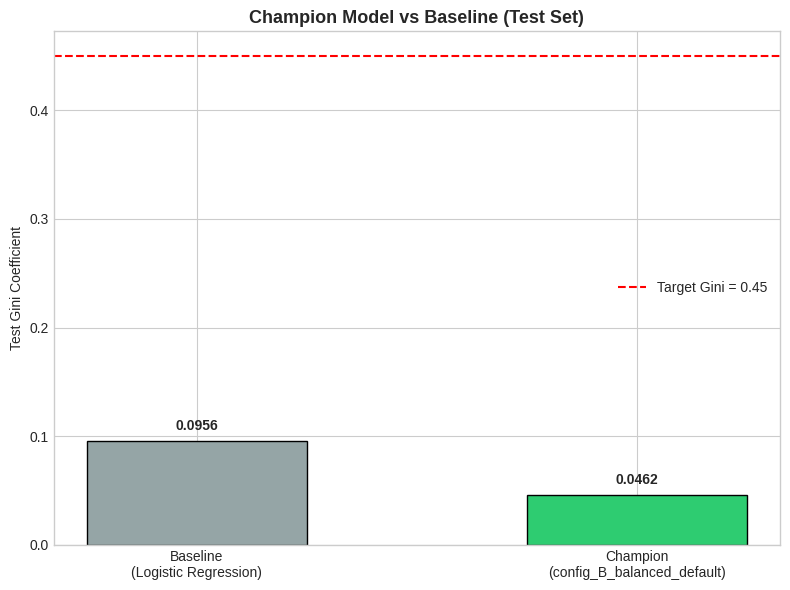

Champion model improves test Gini over baseline by -0.0493 (-51.6% relative)


In [11]:
# Champion vs baseline
fig, ax = plt.subplots(figsize=(8, 6))
labels = ["Baseline\n(Logistic Regression)", f"Champion\n({best_config_name})"]
values = [baseline_test_gini, best_result["test"]["gini"]]
bars = ax.bar(labels, values, color=["#95a5a6", "#2ecc71"], edgecolor="black", width=0.5)
ax.axhline(0.45, color="red", linestyle="--", linewidth=1.5, label="Target Gini = 0.45")
for bar, v in zip(bars, values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f"{v:.4f}", ha="center", fontweight="bold")
ax.set_ylabel("Test Gini Coefficient")
ax.set_title("Champion Model vs Baseline (Test Set)", fontsize=13, fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig("champion_vs_baseline.png", dpi=150, bbox_inches="tight")
plt.show()

lift_over_baseline = best_result["test"]["gini"] - baseline_test_gini
print(f"Champion model improves test Gini over baseline by {lift_over_baseline:+.4f} "
      f"({lift_over_baseline / max(abs(baseline_test_gini), 1e-6):+.1%} relative)")

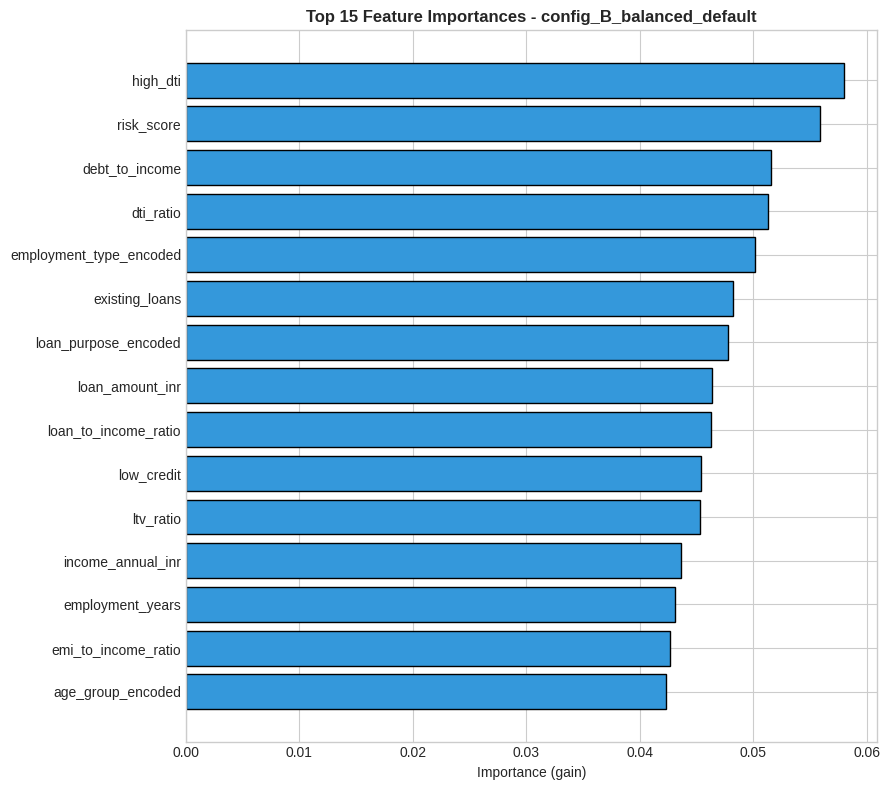

In [12]:
# Feature importance for the winning model
importance_df = pd.DataFrame({
    "feature": X_train.columns,
    "importance": best_model.feature_importances_
}).sort_values("importance", ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(importance_df["feature"][::-1], importance_df["importance"][::-1], color="#3498db", edgecolor="black")
ax.set_xlabel("Importance (gain)")
ax.set_title(f"Top 15 Feature Importances - {best_config_name}", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("champion_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Confusion Matrix + Classification Report (Champion, Test Set)

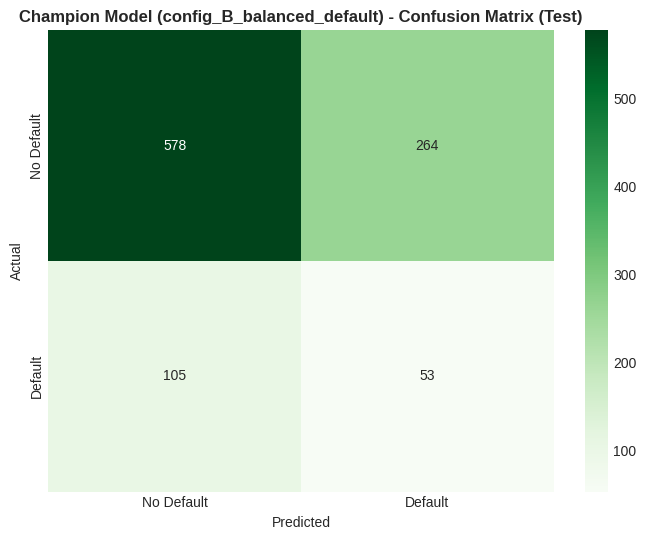

              precision    recall  f1-score   support

  No Default       0.85      0.69      0.76       842
     Default       0.17      0.34      0.22       158

    accuracy                           0.63      1000
   macro avg       0.51      0.51      0.49      1000
weighted avg       0.74      0.63      0.67      1000



In [13]:
test_proba_best = best_model.predict_proba(X_test)[:, 1]
test_pred_best = (test_proba_best >= 0.5).astype(int)

cm = confusion_matrix(y_test, test_pred_best)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", ax=ax,
            xticklabels=["No Default", "Default"], yticklabels=["No Default", "Default"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Champion Model ({best_config_name}) - Confusion Matrix (Test)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.savefig("champion_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

print(classification_report(y_test, test_pred_best, target_names=["No Default", "Default"]))

## 9. Save the Champion Model + Register Best Run

In [14]:
import pickle

Path("artifacts").mkdir(exist_ok=True)

with open("artifacts/champion_model.pkl", "wb") as f:
    pickle.dump(best_model, f)

champion_metadata = {
    "selected_config": best_config_name,
    "selection_criterion": "highest validation Gini (test set untouched during selection)",
    "mlflow_run_id": best_result["run_id"],
    "mlflow_experiment": "finwise_champion_model",
    "hyperparameters": best_result["params"],
    "best_iteration": int(best_result["best_iteration"]),
    "metrics": {
        "train": best_result["train"],
        "val": best_result["val"],
        "test": best_result["test"],
    },
    "baseline_test_gini": baseline_test_gini,
    "gini_lift_over_baseline": lift_over_baseline,
    "target_gini": 0.45,
    "target_met": bool(best_result["test"]["gini"] >= 0.45),
}

with open("artifacts/champion_model_metadata.json", "w") as f:
    json.dump(champion_metadata, f, indent=2, default=str)

print("Saved: artifacts/champion_model.pkl")
print("Saved: artifacts/champion_model_metadata.json")
print("Saved: artifacts/experiment_comparison.csv")

Saved: artifacts/champion_model.pkl
Saved: artifacts/champion_model_metadata.json
Saved: artifacts/experiment_comparison.csv


## 10. Auto-Generate the Experiment Report

In [15]:
target_met_str = "PASSED" if champion_metadata["target_met"] else "NOT YET MET"

report_md = f"""# FinWise Lending — Core Model & Experimentation Report
## Checkpoint 3: Core Model + Experimentation

**Status:** Complete
**Primary model:** XGBoost Classifier
**Configurations tested:** {len(configs)}
**Experiment tracking:** MLflow (`sqlite:///mlflow.db`, experiment `finwise_champion_model`)

---

## 1. Experiment Setup

- **Data pipeline:** reused unchanged from Checkpoint 2 (`data_pipeline.py`),
  including the same fitted preprocessor — no leakage between baseline and
  champion comparisons.
- **Train / Validation / Test sizes:** {len(y_train):,} / {len(y_val):,} / {len(y_test):,}
- **Early stopping:** {EARLY_STOPPING_ROUNDS} rounds on the validation AUC,
  so each configuration's `n_estimators` is a ceiling, not a target.
- **Model selection rule:** the winning configuration is chosen by the
  **highest validation Gini**. The test set is only used afterward, to
  report a final, unbiased performance estimate — it never influences
  which configuration is picked.

---

## 2. Hyperparameter Configurations Tested

{chr(10).join([f"**{name}**: " + ", ".join([f"{k}={v}" for k, v in p.items() if k not in ('scale_pos_weight','random_state','eval_metric')]) for name, p in configs.items()])}

---

## 3. Results — All Configurations (Evidence Table)

{comparison_df.round(4).to_markdown(index=False)}

*(Train-Val Gini Gap is an overfitting signal — a large positive gap means
the model memorized the training set more than it generalized.)*

---

## 4. Selected Configuration

- **Winner:** `{best_config_name}`
- **MLflow run ID:** `{best_result['run_id']}`
- **Selection basis:** highest validation Gini ({best_result['val']['gini']:.4f})
- **Best boosting iteration:** {best_result['best_iteration']} (via early stopping)

**Final test-set performance (unbiased, held out from selection):**

| Metric | Value |
|---|---|
| AUC | {best_result['test']['auc']:.4f} |
| Gini | {best_result['test']['gini']:.4f} |
| KS Statistic | {best_result['test']['ks_statistic']:.4f} |
| Brier Score | {best_result['test']['brier_score']:.4f} |

---

## 5. Champion vs. Baseline

| Model | Test Gini | Test AUC |
|---|---|---|
| Baseline (Logistic Regression, Checkpoint 2) | {baseline_test_gini:.4f} | {baseline_test_auc:.4f} |
| Champion ({best_config_name}) | {best_result['test']['gini']:.4f} | {best_result['test']['auc']:.4f} |
| **Lift** | **{lift_over_baseline:+.4f}** | **{best_result['test']['auc'] - baseline_test_auc:+.4f}** |

**Project acceptance criterion:** Gini >= 0.45 on test set: **{target_met_str}**
({best_result['test']['gini']:.4f} vs. 0.45 target)

---

## 6. Evidence Artifacts Generated

- `experiment_roc_comparison.png` — ROC curves for all 3 configs, winner highlighted
- `experiment_metric_comparison.png` — Gini/AUC/KS bar comparison across configs
- `champion_vs_baseline.png` — champion vs. baseline Gini, with target line
- `champion_feature_importance.png` — top 15 features driving the champion model
- `champion_confusion_matrix.png` — test-set confusion matrix at threshold 0.5
- `artifacts/experiment_comparison.csv` — full metrics table, all configs
- `artifacts/champion_model.pkl` — the selected, trained model
- `artifacts/champion_model_metadata.json` — full config + metrics for the winner
- MLflow run history — `mlflow ui --backend-store-uri sqlite:///mlflow.db`

---

## 7. Next Steps (Checkpoint 4)

- Run SHAP explainability on the champion model (waterfall + summary plots).
- Run the bias/fairness audit (age, employment type, loan purpose) on the
  champion model's predictions.
- Wire the champion model into the FastAPI serving layer.
"""

with open("artifacts/experiment_report.md", "w") as f:
    f.write(report_md)

print("Experiment report saved to artifacts/experiment_report.md")
print("\n" + "=" * 70)
print("CHECKPOINT 3 COMPLETE")
print("=" * 70)
print(f"Best config: {best_config_name}")
print(f"Test Gini: {best_result['test']['gini']:.4f} (target: 0.45, {target_met_str})")
print("View all runs:  mlflow ui --backend-store-uri sqlite:///mlflow.db")

Experiment report saved to artifacts/experiment_report.md

CHECKPOINT 3 COMPLETE
Best config: config_B_balanced_default
Test Gini: 0.0462 (target: 0.45, NOT YET MET)
View all runs:  mlflow ui --backend-store-uri sqlite:///mlflow.db
